# Demanda horaria de bicicletas compartidas
## Proyecto final · Fundamentos de Aprendizaje Automático

**Pregunta:** ¿cuántos alquileres se esperarían durante una hora, dadas las condiciones de calendario y clima del sistema histórico Capital Bikeshare?

Desarrollamos un simulador para una persona que planifica la operación de un servicio de bicicletas. La unidad de análisis es **una hora de todo el sistema**, y la respuesta es el número de **alquileres**, no el inventario de bicicletas. Los datos corresponden a Washington D. C. en 2011–2012. El prototipo permite comparar escenarios históricos; su uso actual exige nuevos datos y otra evaluación.

**Ruta de lectura:** contexto → datos y auditoría → separación temporal → EDA → pipelines → selección → prueba final → explicación y despliegue → reajuste y sustentación.

Las conclusiones y cifras se obtienen de las celdas ejecutadas. Todos los modelos se entrenan al ejecutar este notebook; no se sustituyen los experimentos por resultados precalculados.

## 1. Preparar el entorno de Colab o Python local

En Colab: escoger **CPU**, ejecutar todas las celdas en orden y conservar el notebook con sus salidas. La primera celda descarga la versión `v1.0` del proyecto cuando hace falta e instala las versiones fijadas. Si Colab solicita reiniciar tras la instalación, reiniciar y volver a ejecutar desde esta celda. Localmente, abrir el notebook desde la carpeta del proyecto con el entorno indicado en el README.

Fuente: [UCI Bike Sharing, DOI 10.24432/C5W894](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), licencia CC BY 4.0. La VM de [Colab es temporal](https://research.google.com/colaboratory/faq.html); al final se ofrece la descarga de los artefactos.

In [1]:
from pathlib import Path
import os, sys, subprocess, importlib.util, json, platform

IN_COLAB = importlib.util.find_spec('google.colab') is not None
SOURCE_REPOSITORY = 'https://github.com/Mateoloperaortiz/bike-demand-final-project.git'
SOURCE_REF = 'v1.0'
if IN_COLAB:
    PROJECT_DIR = Path('/content/bike-demand-final-project')
    if not (PROJECT_DIR / 'bike_demand').is_dir():
        subprocess.run(['git', 'clone', '--depth', '1', '--branch', SOURCE_REF,
                        SOURCE_REPOSITORY, str(PROJECT_DIR)], check=True)
else:
    PROJECT_DIR = Path.cwd()
    if not (PROJECT_DIR / 'bike_demand').is_dir():
        raise RuntimeError('Abrir este notebook desde la carpeta que contiene bike_demand/.')
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    '-r', str(PROJECT_DIR / 'requirements-colab.txt')], check=True)
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
print('Python:', platform.python_version())
print('Directorio del proyecto:', PROJECT_DIR)
print('Entorno:', 'Google Colab CPU' if IN_COLAB else 'Python local')

Python: 3.12.14
Directorio del proyecto: S:\Github\Fundamentos_de_Aprendizaje_Automatico_2026-2\TrabajodeMateoLopera\FinalProject_BikeDemand
Entorno: Python local


### Bibliotecas, estilo y parámetros

La semilla es 42. Limitamos el paralelismo a dos trabajos concurrentes y dos hilos nativos para mantener el costo de CPU acotado. Los gráficos usan las mismas unidades y colores en todo el trabajo. Las funciones compartidas con la app están en un paquete importable, por lo que el modelo guardado no depende de clases definidas en celdas.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy, joblib
from IPython.display import display, Markdown
from bike_demand.data import load_dataset, audit_dataset, split_dataset, build_features, split_summary
from bike_demand.training import make_temporal_cv, compare_models, finalize_model
from bike_demand.inference import load_artifacts, scenario_features, predict_demand, WEATHER_LABELS

SEED = 42
JOBS = 2
REPORT_DIR = PROJECT_DIR / 'reportes'
FIGURE_DIR = PROJECT_DIR / 'figuras'
ARTIFACT_DIR = PROJECT_DIR / 'artifacts'
for directory in (REPORT_DIR, FIGURE_DIR, ARTIFACT_DIR):
    directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 4.8), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18, 'figure.dpi': 110})
COLORS = {'Laboral': '#23675b', 'No laboral': '#bf8534',
          'real': '#23675b', 'predicho': '#b47b31', 'base': '#78838a'}

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

print({k: v for k, v in [('numpy', np.__version__), ('pandas', pd.__version__),
                        ('scikit-learn', sklearn.__version__), ('scipy', scipy.__version__),
                        ('joblib', joblib.__version__)]})

{'numpy': '2.2.6', 'pandas': '2.3.3', 'scikit-learn': '1.7.2', 'scipy': '1.16.3', 'joblib': '1.5.2'}


## 2. Problema, usuarios y criterios de evaluación

Un operador necesita anticipar carga de trabajo bajo distintos horarios y condiciones. La interfaz estimará **alquileres/hora**; no decidirá el reparto por estación, porque el dataset está agregado. El clima introducido representa un escenario condicionado: el CSV contiene clima observado y no permite medir el error de un pronóstico meteorológico.

Aplicaremos **aprendizaje supervisado de regresión**. MAE mide cuántos alquileres por hora nos equivocamos, en promedio; es el criterio de selección. RMSE penaliza más los errores grandes, relevantes en horas de alta demanda. R² describe el ajuste respecto a la variabilidad observada, y no equivale a porcentaje de aciertos. La utilidad se contrasta con un predictor constante entrenado con la mediana.

La partición cronológica evalúa generalización hacia meses posteriores dentro del contexto histórico. No demuestra transferencia a otra ciudad ni al año actual. Se mantendrá la prueba final cerrada hasta fijar el ganador y sus parámetros.

## 3. Descargar y auditar los datos originales

La descarga usa el ZIP oficial sin credenciales y verifica SHA-256 tanto del ZIP como del CSV. Un archivo cambiado produce un error, evitando comparar silenciosamente fuentes distintas. La ficha UCI presenta una cifra de filas distinta; usamos la dimensión verificada del archivo original: **17.379 × 17**.

La auditoría de estructura del archivo completo verifica integridad y cobertura. El análisis exploratorio que guía el modelado se hace después, únicamente con entrenamiento.

In [3]:
df = load_dataset(PROJECT_DIR / 'data')
audit = audit_dataset(df)
(REPORT_DIR / 'auditoria_datos.json').write_text(
    json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')
display(df.head())
display(pd.DataFrame([{'Filas': len(df), 'Columnas originales': 17,
                      'Fechas-horas duplicadas': audit['duplicate_date_hour_rows'],
                      'Horas ausentes': audit['absent_hours'],
                      'Días con horas ausentes': audit['days_with_absent_hours']}]))
display(pd.Series(audit['missing_values'], name='Valores faltantes').to_frame())
assert len(df) == 17379
assert audit['target_components_equal_total']

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,timestamp
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01 03:00:00
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01 04:00:00


,Filas,Columnas originales,Fechas-horas duplicadas,Horas ausentes,Días con horas ausentes
0,17379,17,0,165,76


,Valores faltantes
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


### Diccionario y decisiones de preprocesamiento

| Variables | Significado y tratamiento |
|---|---|
| `cnt` | Alquileres totales por hora; variable objetivo. |
| `instant`, `casual`, `registered` | Identificador y componentes del objetivo; se excluyen. `casual + registered = cnt` sería fuga directa. |
| `dteday` | Fecha para ordenar, separar y derivar calendario; no entra como texto al modelo. |
| `yr`, `mnth`, `hr`, `weekday` | Año histórico, mes, hora y día de la semana. |
| `holiday`, `workingday` | Festivo y día laboral del calendario original de Washington. |
| `weathersit` | Claro, neblina o lluvia. El código 4 se agrupa con lluvia por escasa representación. |
| `temp`, `hum`, `windspeed` | Temperatura, humedad y viento en las escalas originales normalizadas. |
| `season`, `atemp` | Se excluyen: el mes y temperatura ya aportan información relacionada; además hay discrepancias documentales en etiquetas/unidades. |

Las **165 horas ausentes** se conservan como ausencia de observación, sin inventar demanda cero. El archivo original no contiene valores faltantes en campos; documentamos que no requiere imputación. Los picos pueden ser demanda legítima: el IQR se usará para describirlos, sin eliminarlos por su valor objetivo. En la interfaz la temperatura y el viento se presentan mediante niveles relativos al historial, evitando atribuir unidades físicas inciertas.

## 4. Reservar validación y prueba antes del EDA

Todas las filas de una misma fecha permanecen juntas. Las transformaciones que aprenden estadísticas se ajustan en entrenamiento y dentro de cada fold. El acceso a columnas de calendario para la interfaz no utiliza la demanda objetivo.

In [4]:
partitions = split_dataset(df)
train = partitions['train']
validation = partitions['validation']
test = partitions['test']
partition_table = split_summary(partitions)
display(partition_table)
partition_table.to_csv(REPORT_DIR / 'particiones.csv', index=False)
assert (len(train), len(validation), len(test)) == (13003, 2208, 2168)
assert pd.to_datetime(train['dteday']).max() < pd.to_datetime(validation['dteday']).min()
assert pd.to_datetime(validation['dteday']).max() < pd.to_datetime(test['dteday']).min()
display(build_features(train).head())

,split,rows,days,start,end
0,train,13003,547,2011-01-01,2012-06-30
1,validation,2208,92,2012-07-01,2012-09-30
2,test,2168,92,2012-10-01,2012-12-31


,yr,mnth,hr,weekday,holiday,workingday,weathersit,temp,hum,windspeed
0,0,1,0,6,0,0,1,0.24,0.81,0.0
1,0,1,1,6,0,0,1,0.22,0.80,0.0
2,0,1,2,6,0,0,1,0.22,0.80,0.0
3,0,1,3,6,0,0,1,0.24,0.75,0.0
4,0,1,4,6,0,0,1,0.24,0.75,0.0


## 5. EDA profundo sobre entrenamiento
### 5.1 Distribución de la demanda y valores extremos

Observamos escala, asimetría y picos antes de elegir métricas y modelos. El umbral IQR se calcula exclusivamente con entrenamiento.

,cnt,temp,hum,windspeed
count,13003.000,13003.000,13003.000,13003.000
mean,167.713,0.482,0.624,0.196
std,160.785,0.191,0.200,0.124
min,1.000,0.020,0.000,0.000
25%,35.000,0.320,0.470,0.104
50%,124.000,0.480,0.620,0.194
75%,246.000,0.640,0.790,0.284
max,957.000,0.980,1.000,0.851


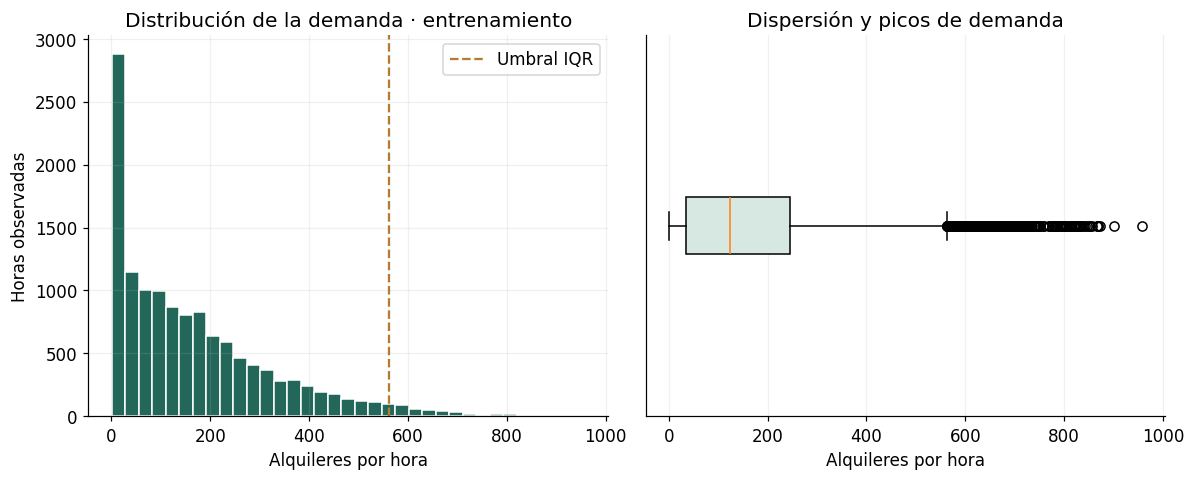

**Hallazgo:** la mediana es **124** alquileres/hora y el máximo es **957**. Hay **406** horas sobre el umbral IQR (562.5). Conservar esos picos permite evaluar el error en alta demanda; MAE resume el error habitual y RMSE revela errores grandes.

In [5]:
display(train[['cnt', 'temp', 'hum', 'windspeed']].describe().round(3))
q1, q3 = train['cnt'].quantile([.25, .75])
iqr_limit = q3 + 1.5 * (q3 - q1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(train['cnt'], bins=35, color=COLORS['real'], edgecolor='white')
axes[0].axvline(iqr_limit, color=COLORS['predicho'], linestyle='--', label='Umbral IQR')
axes[0].set(xlabel='Alquileres por hora', ylabel='Horas observadas', title='Distribución de la demanda · entrenamiento')
axes[0].legend()
axes[1].boxplot(train['cnt'], orientation='horizontal', patch_artist=True,
                boxprops={'facecolor': '#d7e8e2'})
axes[1].set(xlabel='Alquileres por hora', title='Dispersión y picos de demanda', yticks=[])
save_figure('01_distribucion_demanda')
display(Markdown(f'**Hallazgo:** la mediana es **{train.cnt.median():.0f}** alquileres/hora y el máximo '
                 f'es **{train.cnt.max():.0f}**. Hay **{(train.cnt > iqr_limit).sum()}** horas sobre el umbral '
                 f'IQR ({iqr_limit:.1f}). Conservar esos picos permite evaluar el error en alta demanda; '
                 'MAE resume el error habitual y RMSE revela errores grandes.'))

### 5.2 Ciclo horario y diferencia entre días laborales

Comparamos promedios horarios con sus volúmenes observados. Los promedios describen asociaciones, no efectos causales.

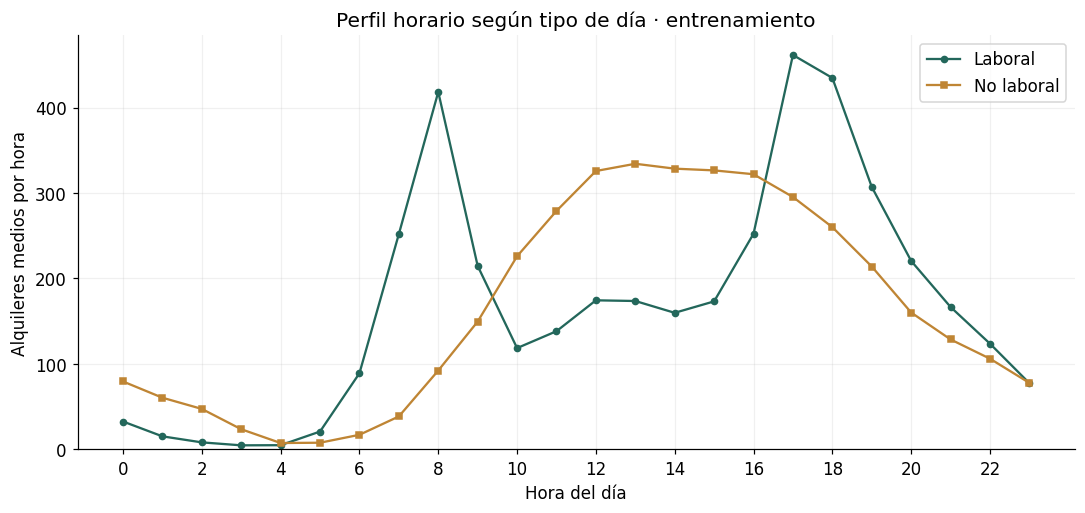

,Hora pico,workingday,Media,median,Horas observadas
26,13,0,334.32,344.0,172
35,17,1,461.73,489.0,375


**Hallazgo:** el máximo promedio ocurre a las **17:00** en días laborales y a las **13:00** en días no laborales. La relación no es lineal con la hora; la codificaremos como categoría y compararemos modelos que puedan aprender interacciones.

In [6]:
hour_profile = train.groupby(['hr', 'workingday'])['cnt'].agg(['mean', 'median', 'count']).reset_index()
fig, ax = plt.subplots()
for flag, label, marker in [(1, 'Laboral', 'o'), (0, 'No laboral', 's')]:
    subset = hour_profile[hour_profile.workingday == flag]
    ax.plot(subset.hr, subset['mean'], label=label, color=COLORS[label], marker=marker, markersize=4)
ax.set(xlabel='Hora del día', ylabel='Alquileres medios por hora', xticks=range(0, 24, 2),
       title='Perfil horario según tipo de día · entrenamiento', ylim=(0, None))
ax.legend()
save_figure('02_perfil_horario')
peaks = hour_profile.loc[hour_profile.groupby('workingday')['mean'].idxmax()]
display(peaks.rename(columns={'hr': 'Hora pico', 'mean': 'Media', 'count': 'Horas observadas'}).round(2))
peak_work = int(peaks.loc[peaks.workingday == 1, 'hr'].iloc[0])
peak_off = int(peaks.loc[peaks.workingday == 0, 'hr'].iloc[0])
display(Markdown(f'**Hallazgo:** el máximo promedio ocurre a las **{peak_work}:00** en días laborales '
                 f'y a las **{peak_off}:00** en días no laborales. La relación no es lineal con la hora; '
                 'la codificaremos como categoría y compararemos modelos que puedan aprender interacciones.'))

### 5.3 Evolución mensual y calendario

Entrenamiento contiene todo 2011 y el primer semestre de 2012. Comparamos medias por hora, en lugar de totales de meses con diferente cobertura.

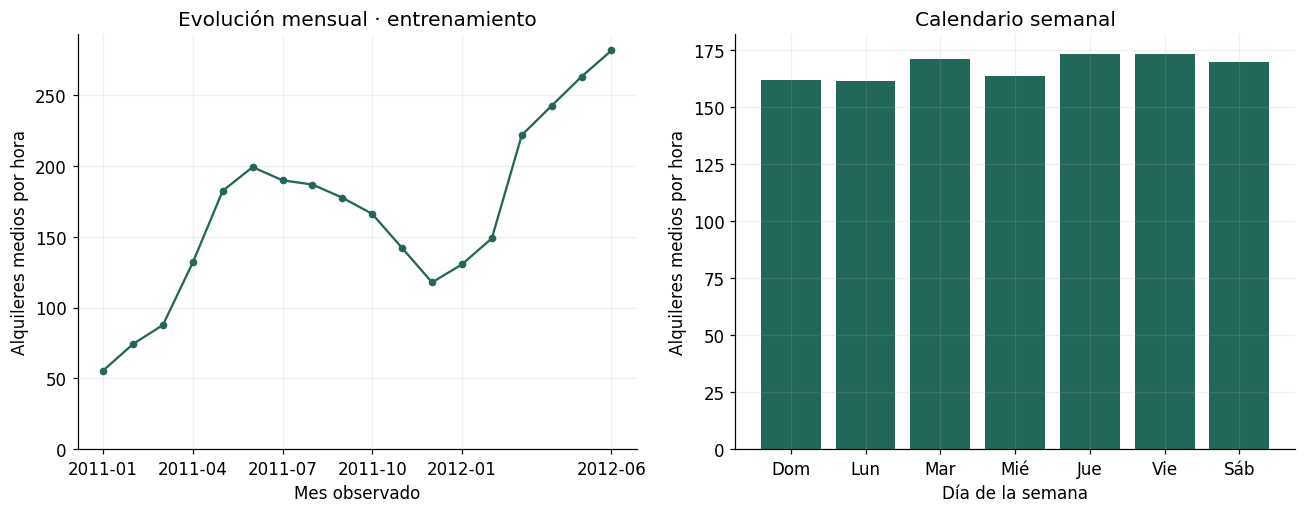

,mean,count
mes_fecha,,
2011-01,55.51,688
2011-02,74.29,649
2011-03,87.73,730
2011-04,131.95,719
2011-05,182.56,744
2011-06,199.32,720
2011-07,189.97,744
2011-08,186.99,731
2011-09,177.71,717


**Decisión:** conservar mes, año histórico y calendario laboral. Los cambios mensuales mezclan estacionalidad, clima y evolución del servicio; no atribuimos causalidad a una sola variable. Una evaluación cronológica permite observar si el modelo se mantiene en meses posteriores.

In [7]:
eda = train.copy()
eda['mes_fecha'] = pd.to_datetime(eda['dteday']).dt.to_period('M').astype(str)
monthly = eda.groupby('mes_fecha')['cnt'].agg(['mean', 'count'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(range(len(monthly)), monthly['mean'], color=COLORS['real'], marker='o', markersize=4)
ticks = list(range(0, len(monthly), 3))
if len(monthly)-1 not in ticks:
    if len(monthly)-1 - ticks[-1] < 3: ticks.pop()
    ticks.append(len(monthly)-1)
axes[0].set(xticks=ticks, xticklabels=[monthly.index[i] for i in ticks],
            ylabel='Alquileres medios por hora', xlabel='Mes observado',
            title='Evolución mensual · entrenamiento', ylim=(0, None))
week = train.groupby('weekday')['cnt'].mean().reindex(range(7))
axes[1].bar(['Dom', 'Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb'], week, color=COLORS['real'])
axes[1].set(ylabel='Alquileres medios por hora', xlabel='Día de la semana', title='Calendario semanal')
save_figure('03_calendario')
display(monthly.round(2))
display(Markdown('**Decisión:** conservar mes, año histórico y calendario laboral. Los cambios mensuales '
                 'mezclan estacionalidad, clima y evolución del servicio; no atribuimos causalidad a una sola variable. '
                 'Una evaluación cronológica permite observar si el modelo se mantiene en meses posteriores.'))

### 5.4 Clima y tamaño de los grupos

Se agrupan los escasos eventos del código 4 con lluvia. Los volúmenes se muestran para evitar interpretar grupos pequeños con la misma confianza que grupos grandes.

,mean,median,count
Despejado o parcialmente nublado,183.44,142.0,8595
Neblina o nublado,151.96,114.0,3276
Lluvia o nieve,93.87,56.0,1132


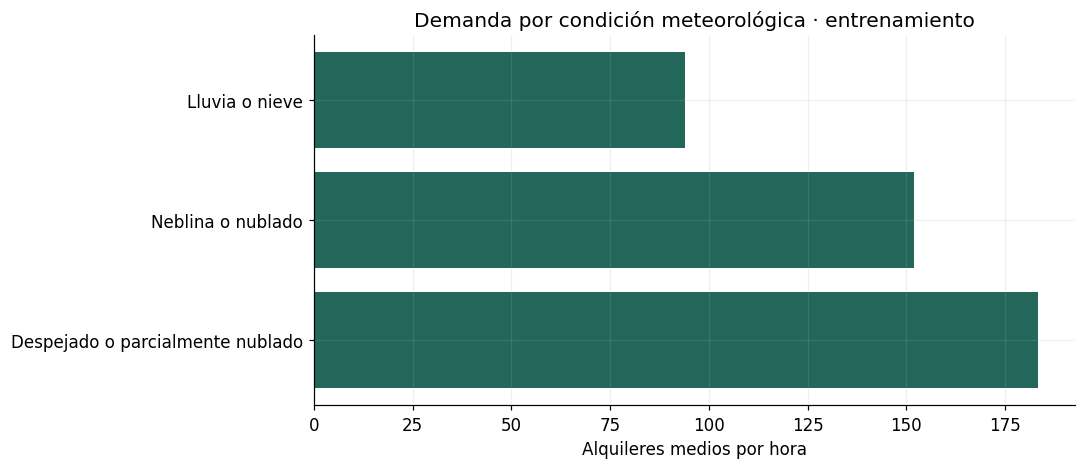

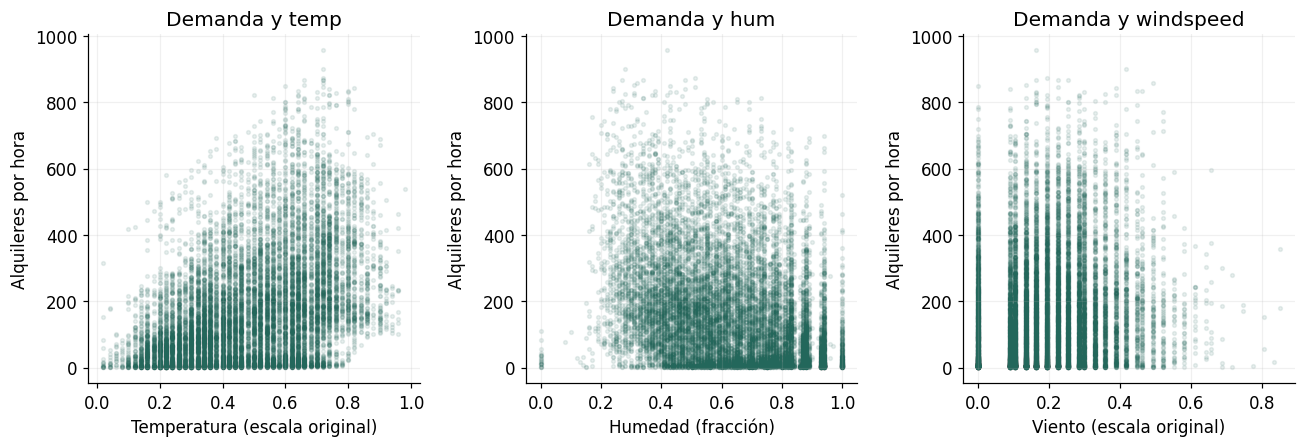

**Decisión:** conservar clima junto con calendario, usando modelos con interacciones. Estas asociaciones están condicionadas por hora, estación y otros factores; la app mostrará escenarios, sin afirmar que modificar el clima causa un cambio determinado.

In [8]:
weather = train.assign(weather_group=train.weathersit.replace({4: 3}))
weather_stats = weather.groupby('weather_group')['cnt'].agg(['mean', 'median', 'count'])
weather_stats.index = [WEATHER_LABELS[int(i)] for i in weather_stats.index]
display(weather_stats.round(2))
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.barh(weather_stats.index, weather_stats['mean'], color=COLORS['real'])
ax.set(xlabel='Alquileres medios por hora', title='Demanda por condición meteorológica · entrenamiento', xlim=(0, None))
save_figure('04_condicion_meteorologica')
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, feature, label in zip(axes, ['temp', 'hum', 'windspeed'],
                            ['Temperatura (escala original)', 'Humedad (fracción)', 'Viento (escala original)']):
    ax.scatter(train[feature], train.cnt, s=6, alpha=.10, color=COLORS['real'], rasterized=True)
    ax.set(xlabel=label, ylabel='Alquileres por hora', title=f'Demanda y {feature}')
save_figure('05_relaciones_clima')
display(Markdown('**Decisión:** conservar clima junto con calendario, usando modelos con interacciones. '
                 'Estas asociaciones están condicionadas por hora, estación y otros factores; '
                 'la app mostrará escenarios, sin afirmar que modificar el clima causa un cambio determinado.'))

### 5.5 Interacciones y correlación

La matriz de hora × día de la semana muestra patrones que un coeficiente lineal aislado no resume. Las correlaciones se calculan sobre variables numéricas, evitando asignar una distancia arbitraria a categorías.

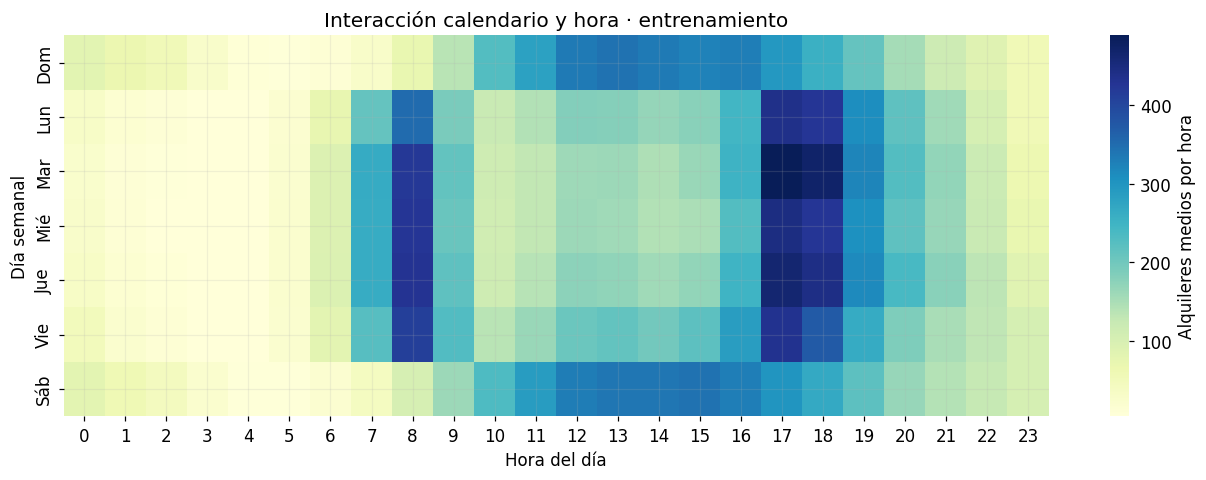

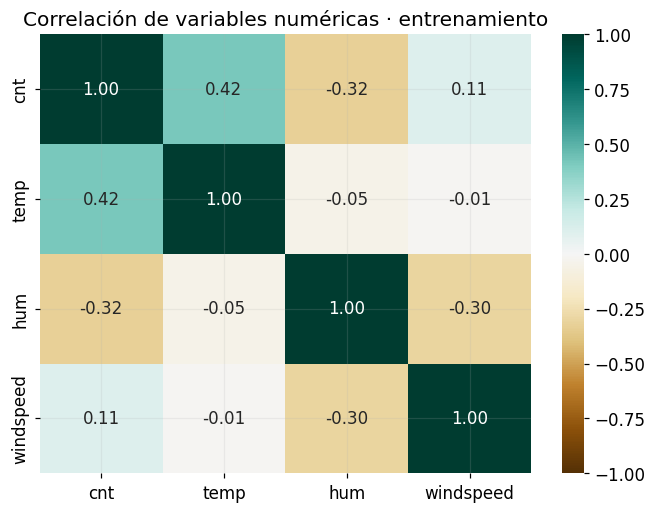

**Síntesis del EDA:** el calendario tiene ciclos y la demanda presenta dispersión bajo el mismo clima. Se comparará una referencia constante, un modelo lineal regularizado y dos ensambles capaces de capturar interacciones. Conservamos los picos y ajustamos codificación/escalado dentro de cada fold.

In [9]:
heat = train.pivot_table(index='weekday', columns='hr', values='cnt', aggfunc='mean').reindex(range(7))
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(heat, cmap='YlGnBu', ax=ax, yticklabels=['Dom', 'Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb'],
            cbar_kws={'label': 'Alquileres medios por hora'})
ax.set(xlabel='Hora del día', ylabel='Día semanal', title='Interacción calendario y hora · entrenamiento')
save_figure('06_interaccion_hora_dia')
fig, ax = plt.subplots(figsize=(6.2, 4.8))
sns.heatmap(train[['cnt', 'temp', 'hum', 'windspeed']].corr(), annot=True, fmt='.2f',
            cmap='BrBG', vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title('Correlación de variables numéricas · entrenamiento')
save_figure('07_correlaciones')
display(Markdown('**Síntesis del EDA:** el calendario tiene ciclos y la demanda presenta dispersión bajo '
                 'el mismo clima. Se comparará una referencia constante, un modelo lineal regularizado '
                 'y dos ensambles capaces de capturar interacciones. Conservamos los picos y ajustamos '
                 'codificación/escalado dentro de cada fold.'))

## 6. Metodología: pipelines y validación temporal

Los modelos reciben las mismas diez variables. Ridge usa codificación one-hot y estandarización de numéricas; los ensambles usan one-hot y numéricas sin escalado. Son transformaciones ajustadas con `Pipeline` y `ColumnTransformer` dentro de la búsqueda. El año histórico permanece binario.

La validación cruzada usa cinco ventanas consecutivas de **30 días completos**, dentro de entrenamiento, con una separación de **dos días** y entrenamiento expansivo. Primero se dividen las fechas únicas y luego se recuperan las filas existentes: las horas ausentes no se sustituyen por ceros. [Ejemplo temporal de scikit-learn](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html).

In [10]:
cv_folds, cv_calendar = make_temporal_cv(train)
display(cv_calendar)
cv_calendar.to_csv(REPORT_DIR / 'calendario_cv.csv', index=False)
assert len(cv_folds) == 5
for train_idx, fold_idx in cv_folds:
    fold_train_dates = pd.to_datetime(train.iloc[train_idx]['dteday'])
    fold_val_dates = pd.to_datetime(train.iloc[fold_idx]['dteday'])
    assert (fold_val_dates.min() - fold_train_dates.max()).days == 3
    assert fold_val_dates.nunique() == 30

,fold,train_start,train_end,train_rows,train_days,validation_start,validation_end,validation_rows,validation_days,gap_days
0,1,2011-01-01,2012-01-30,9362,395,2012-02-02,2012-03-02,716,30,2
1,2,2011-01-01,2012-02-29,10078,425,2012-03-03,2012-04-01,719,30,2
2,3,2011-01-01,2012-03-30,10797,455,2012-04-02,2012-05-01,718,30,2
3,4,2011-01-01,2012-04-29,11515,485,2012-05-02,2012-05-31,720,30,2
4,5,2011-01-01,2012-05-29,12235,515,2012-06-01,2012-06-30,720,30,2


### Comparaciones e hiperparámetros

| Modelo | Búsqueda acotada | Motivo |
|---|---|---|
| Mediana constante | Sin búsqueda | Referencia que minimiza error absoluto entre predicciones constantes. |
| Ridge | α = 0,1; 1; 10; 100 | Referencia lineal regularizada y rápida. |
| Random Forest | 200 árboles; profundidad 10/20/sin límite; hoja mínima 1/5 | Seis combinaciones para capturar interacciones y controlar complejidad. |
| HistGradientBoosting | Tasas 0,05/0,1; hojas 15/31; hoja mínima 10/20 | Ocho combinaciones, 200 iteraciones y detención temprana aleatoria desactivada. |

La búsqueda escoge parámetros por MAE medio de CV. Luego cada familia se compara en julio–septiembre. Se selecciona el menor MAE de validación, con RMSE como desempate. El recorte de predicciones a cero se aplica igual en búsqueda, evaluación y app; el redondeo solo se usa al presentar una estimación.

**Esta celda realiza el entrenamiento real.** En CPU puede tardar varios minutos.

In [11]:
development = compare_models(train, validation, report_dir=REPORT_DIR, jobs=JOBS)
comparison = development['comparison']
display(comparison.drop(columns=['best_params']).round(3))
display(development['cv_summary'].round(3))
winner_name = development['winner_name']
display(Markdown(f'**Ganador fijado antes de prueba:** {winner_name}. '
                 'Los parámetros se presentan a continuación; la prueba no intervino en esta selección.'))
display(comparison[['model', 'best_params']])

Evaluando referencia de mediana en cinco bloques temporales…


Ajustando Ridge: 4 configuraciones × cinco bloques…


Ajustando Random Forest: 6 configuraciones × cinco bloques…


Ajustando Gradient Boosting: 8 configuraciones × cinco bloques…


Ganador por validación: Gradient Boosting. Explicando sus errores sin usar prueba…


,model,train_mae,train_rmse,train_r2,val_mae,val_rmse,val_r2,cv_mae_mean,cv_mae_std
0,Gradient Boosting,22.397,33.381,0.957,47.149,68.398,0.912,62.249,13.427
1,Random Forest,10.705,17.322,0.988,48.044,72.695,0.901,62.160,15.412
2,Ridge,61.789,87.474,0.704,111.212,145.995,0.601,91.283,19.255
3,Mediana,121.677,166.616,-0.074,213.699,283.543,-0.506,172.676,36.981


,model,cv_mae_mean,cv_mae_std,best_params
0,Mediana,172.676,36.981,{}
1,Ridge,91.283,19.255,"{""model__alpha"": 0.1}"
2,Random Forest,62.160,15.412,"{""model__max_depth"": null, ""model__min_samples..."
3,Gradient Boosting,62.249,13.427,"{""model__learning_rate"": 0.1, ""model__max_leaf..."


**Ganador fijado antes de prueba:** Gradient Boosting. Los parámetros se presentan a continuación; la prueba no intervino en esta selección.

,model,best_params
0,Gradient Boosting,"{""model__learning_rate"": 0.1, ""model__max_leaf..."
1,Random Forest,"{""model__max_depth"": null, ""model__min_samples..."
2,Ridge,"{""model__alpha"": 0.1}"
3,Mediana,{}


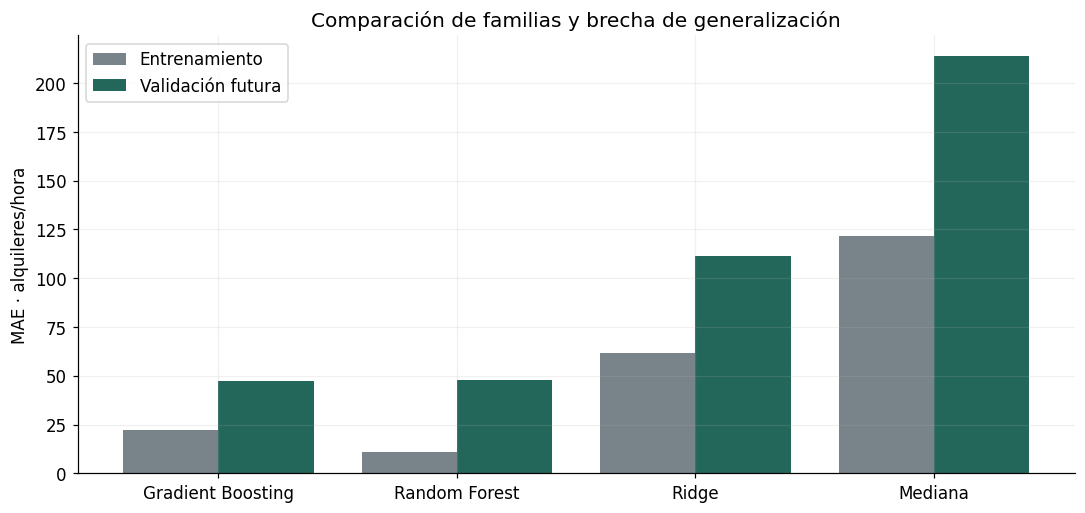

**Interpretación:** Gradient Boosting tiene MAE de entrenamiento **22.40** y de validación **47.15**. La CV temporal arroja **62.25 ± 13.43**. La variabilidad entre ventanas y la brecha temporal se reportan como límites; el desempeño de CV no es una evaluación anidada de todo el proceso de selección.

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(comparison))
ax.bar(x-.2, comparison.train_mae, .4, label='Entrenamiento', color=COLORS['base'])
ax.bar(x+.2, comparison.val_mae, .4, label='Validación futura', color=COLORS['real'])
ax.set(xticks=x, xticklabels=comparison.model, ylabel='MAE · alquileres/hora',
       title='Comparación de familias y brecha de generalización')
ax.legend()
save_figure('08_comparacion_modelos')
best_row = comparison.loc[comparison.model == winner_name].iloc[0]
display(Markdown(f'**Interpretación:** {winner_name} tiene MAE de entrenamiento '
                 f'**{best_row.train_mae:.2f}** y de validación **{best_row.val_mae:.2f}**. '
                 f'La CV temporal arroja **{best_row.cv_mae_mean:.2f} ± {best_row.cv_mae_std:.2f}**. '
                 'La variabilidad entre ventanas y la brecha temporal se reportan como límites; '
                 'el desempeño de CV no es una evaluación anidada de todo el proceso de selección.'))

## 7. Explicación del modelo elegido

La importancia por permutación se calcula en validación antes del reajuste final: se altera una entrada y se mide cuánto empeora MAE. Es una medida predictiva, no causal, y puede repartirse entre variables correlacionadas. No se usa para cambiar variables después de seleccionar el modelo.

,feature,importance_mean,importance_std
0,hr,168.690,3.087
1,workingday,39.703,2.160
2,hum,25.143,0.855
3,weekday,7.358,0.412
4,temp,6.914,0.373
5,weathersit,2.418,0.244
6,holiday,0.516,0.069
7,windspeed,0.327,0.179
8,mnth,0.052,0.051
9,yr,0.000,0.000


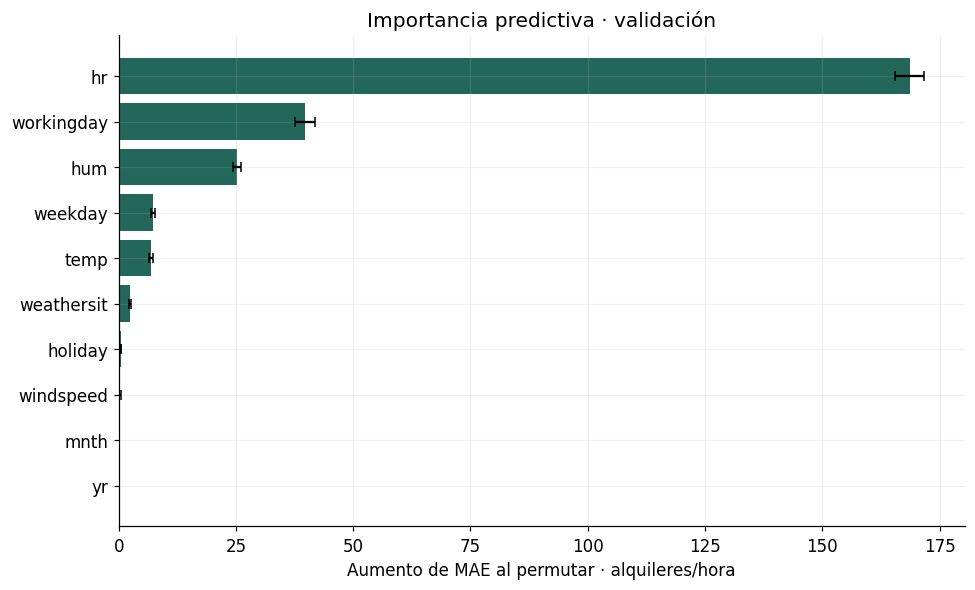

**Hallazgo:** las entradas con mayor aumento del error al permutarlas son **hr, workingday, hum**. La explicación ayuda a sostener las variables del formulario, pero no justifica decisiones causales.

In [13]:
importance = development['permutation_importance'].sort_values('importance_mean')
display(importance.sort_values('importance_mean', ascending=False).round(3))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importance.feature, importance.importance_mean, xerr=importance.importance_std,
        color=COLORS['real'], capsize=3)
ax.axvline(0, color='#37454a', linewidth=1)
ax.set(xlabel='Aumento de MAE al permutar · alquileres/hora', title='Importancia predictiva · validación')
save_figure('09_importancia_permutacion')
display(Markdown('**Hallazgo:** las entradas con mayor aumento del error al permutarlas son **' +
                 ', '.join(importance.tail(3).iloc[::-1].feature) + '**. '
                 'La explicación ayuda a sostener las variables del formulario, pero no justifica decisiones causales.'))

## 8. Reajuste final y evaluación única en prueba

Con la familia y parámetros ya fijados, se ajusta un nuevo pipeline con enero de 2011–septiembre de 2012. La mediana de referencia se reajusta con los mismos datos. Solo entonces se evalúan octubre–diciembre. El artefacto publicado es exactamente el evaluado: la prueba permanece fuera de su ajuste.

In [14]:
final = finalize_model(development, train, validation, test, df,
                       artifact_dir=ARTIFACT_DIR, report_dir=REPORT_DIR)
display(final['metrics'].round(3))
predictions = final['test_predictions']
segments = final['error_segments']
display(segments.round(3))
metadata = final['metadata']
performance = metadata['performance']
baseline_row = final['metrics'].loc[final['metrics'].model != winner_name].iloc[0]
improvement = 100 * (1 - performance['mae'] / baseline_row.mae)
display(Markdown(f'**Resultado final:** {winner_name} obtiene MAE **{performance["mae"]:.2f}** alquileres/hora, '
                 f'RMSE **{performance["rmse"]:.2f}** y R² **{performance["r2"]:.3f}** en 2.168 horas posteriores. '
                 f'La mejora de MAE frente a la mediana es **{improvement:.1f}%**. '
                 'Este resultado respalda la estimación en el dominio histórico evaluado, con el clima observado como entrada.'))

Reajustando Gradient Boosting con 15211 filas. Prueba final: 2168 filas…


,model,mae,rmse,r2,rows
0,Gradient Boosting,52.619,76.965,0.854,2168
1,Mediana,158.814,217.324,-0.162,2168


,segment,value,rows,mae,rmse,bias
0,hr,0,91,23.093,39.793,-9.615
1,hr,1,90,18.244,28.058,-8.400
2,hr,2,90,13.949,21.088,-1.611
3,hr,3,87,8.673,13.597,-1.043
4,hr,4,89,6.236,7.578,-0.217
5,hr,5,90,12.111,15.592,-7.693
6,hr,6,90,25.659,32.429,-15.148
7,hr,7,90,72.949,89.611,-33.668
8,hr,8,90,115.452,149.051,-43.766
9,hr,9,90,60.740,72.147,-26.365


**Resultado final:** Gradient Boosting obtiene MAE **52.62** alquileres/hora, RMSE **76.97** y R² **0.854** en 2.168 horas posteriores. La mejora de MAE frente a la mediana es **66.9%**. Este resultado respalda la estimación en el dominio histórico evaluado, con el clima observado como entrada.

### Errores y límites de desempeño

Contrastamos predicción con demanda observada y revisamos sesgo por hora y condición meteorológica. Los grupos pequeños se acompañan de su número de observaciones.

Columnas de predicciones: ['timestamp', 'cnt', 'yr', 'mnth', 'hr', 'weekday', 'holiday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'prediction', 'baseline_prediction', 'residual', 'absolute_error']


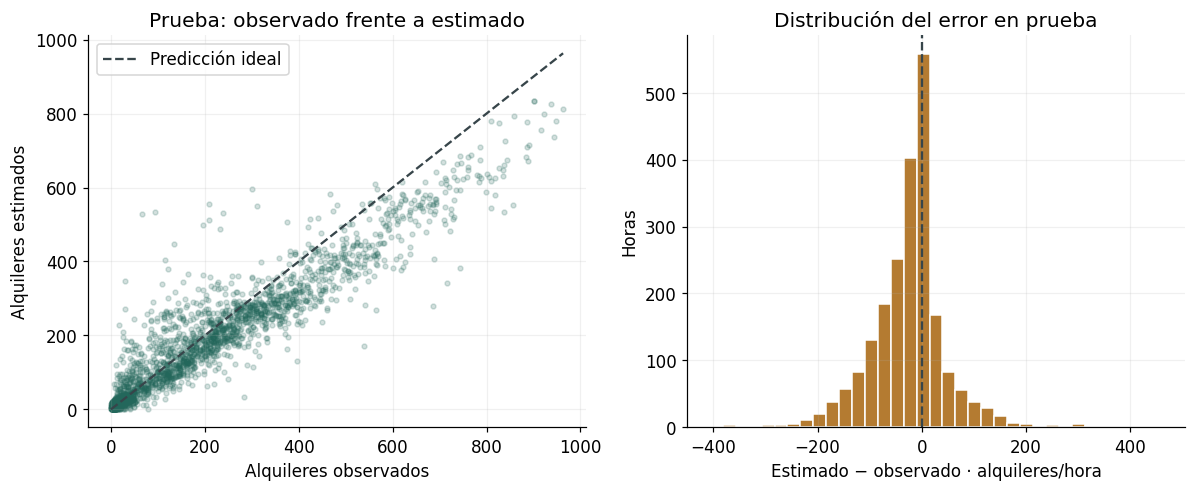

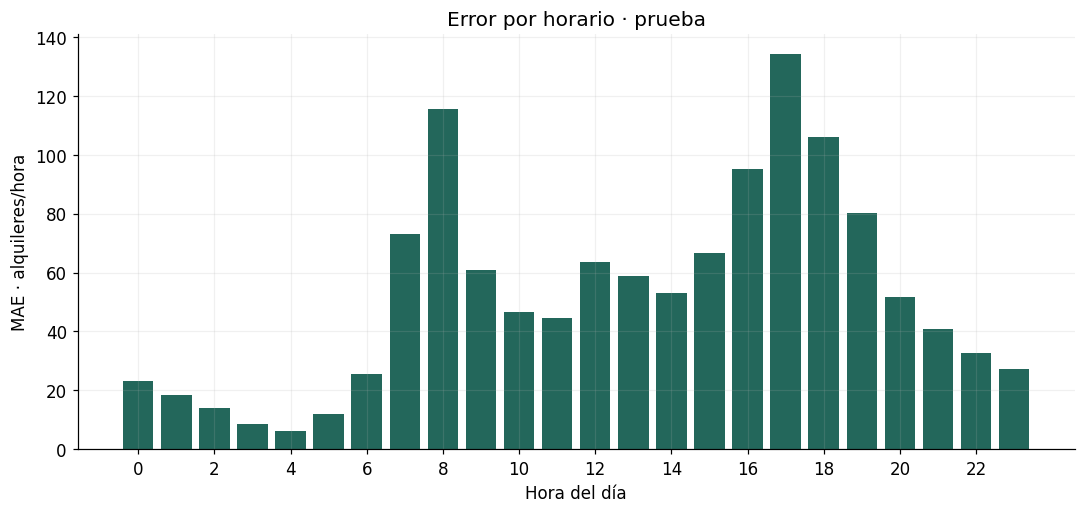

,MAE,Sesgo,N
hora,,,
0,23.09,-9.62,91
1,18.24,-8.40,90
2,13.95,-1.61,90
3,8.67,-1.04,87
4,6.24,-0.22,89
5,12.11,-7.69,90
6,25.66,-15.15,90
7,72.95,-33.67,90
8,115.45,-43.77,90


**Límite operativo:** el mayor MAE horario ocurre a las **17:00**, con **134.21** alquileres/hora de error medio (91 horas observadas). La estimación debe apoyar la planificación y revisarse cuando cambie el contexto.

In [15]:
print('Columnas de predicciones:', list(predictions.columns))
# Usar el artefacto recién ajustado evita depender de nombres internos del reporte.
y_true = test['cnt'].to_numpy()
y_pred = predict_demand(final['model'], build_features(test))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].scatter(y_true, y_pred, alpha=.20, s=10, color=COLORS['real'])
limit = max(y_true.max(), y_pred.max())
axes[0].plot([0, limit], [0, limit], '--', color='#37454a', label='Predicción ideal')
axes[0].set(xlabel='Alquileres observados', ylabel='Alquileres estimados', title='Prueba: observado frente a estimado')
axes[0].legend()
axes[1].hist(y_pred-y_true, bins=35, color=COLORS['predicho'], edgecolor='white')
axes[1].axvline(0, color='#37454a', linestyle='--')
axes[1].set(xlabel='Estimado − observado · alquileres/hora', ylabel='Horas', title='Distribución del error en prueba')
save_figure('10_errores_prueba')
errors = pd.DataFrame({'hora': test.hr.to_numpy(), 'error_abs': np.abs(y_true-y_pred),
                       'sesgo': y_pred-y_true})
by_hour = errors.groupby('hora').agg(MAE=('error_abs', 'mean'), Sesgo=('sesgo', 'mean'), N=('error_abs', 'size'))
fig, ax = plt.subplots()
ax.bar(by_hour.index, by_hour.MAE, color=COLORS['real'])
ax.set(xlabel='Hora del día', ylabel='MAE · alquileres/hora', xticks=range(0, 24, 2), title='Error por horario · prueba')
save_figure('11_error_horario')
display(by_hour.round(2))
worst_hour = int(by_hour.MAE.idxmax())
display(Markdown(f'**Límite operativo:** el mayor MAE horario ocurre a las **{worst_hour}:00**, '
                 f'con **{by_hour.loc[worst_hour, "MAE"]:.2f}** alquileres/hora de error medio '
                 f'({int(by_hour.loc[worst_hour, "N"])} horas observadas). '
                 'La estimación debe apoyar la planificación y revisarse cuando cambie el contexto.'))

## 9. Persistencia, equivalencia con la app e interfaz

El pipeline completo se guarda con `joblib`, acompañado de versiones, esquema, fuente, métricas y niveles climáticos calculados solo sobre los datos de ajuste final. La app deriva calendario, toma festivos históricos y utiliza la misma función de inferencia. Se conservan cinco casos de referencia para comprobar equivalencia al recargar el modelo.

La interfaz muestra una estimación por hora y ejemplos precargados. Su MAE es un resultado global de evaluación; no es un intervalo de confianza de cada predicción. La app solo realiza inferencia y recupera el modelo desde el repositorio tras reinicios.

In [16]:
reloaded_model, reloaded_metadata = load_artifacts(ARTIFACT_DIR)
reference = build_features(test.head(5))
np.testing.assert_allclose(predict_demand(final['model'], reference),
                           predict_demand(reloaded_model, reference), rtol=1e-6, atol=1e-6)
example_rows = []
for example in reloaded_metadata['examples']:
    inputs = {k: example[k] for k in ['date', 'hour', 'weather', 'thermal_level', 'humidity_pct', 'wind_level']}
    example_features = scenario_features(**inputs, metadata=reloaded_metadata)
    estimate = float(predict_demand(reloaded_model, example_features)[0])
    example_rows.append({'Escenario': example['name'], 'Alquileres estimados/hora': round(estimate, 1)})
display(pd.DataFrame(example_rows))
print('Equivalencia del modelo recargado: verificada.')
print('Tamaño del modelo:', round((ARTIFACT_DIR / 'model.joblib').stat().st_size / 1024**2, 2), 'MiB')
print('App local: python -m streamlit run streamlit_app.py')

,Escenario,Alquileres estimados/hora
0,Mañana laboral,721.3
1,Sábado cálido,572.3
2,Tarde con lluvia,358.0


Equivalencia del modelo recargado: verificada.
Tamaño del modelo: 0.28 MiB
App local: python -m streamlit run streamlit_app.py


## 10. Estrategia de reajuste y operación

La estrategia completa está en `docs/estrategia_reajuste.md`. En una operación real se requerirían alquileres observados posteriores a la predicción para medir desempeño.

1. **Revisión mensual:** MAE global y por horario/clima, cobertura y cambios de distribución de las entradas.
2. **Señal inicial:** investigar un aumento de MAE superior al 20% de la referencia durante dos meses consecutivos. El umbral es un supuesto operativo, no un resultado estimado del dataset.
3. **Revisión trimestral:** decidir si hay datos suficientes y razones para reentrenar. Un cambio en entradas sin demanda observada no demuestra degradación por sí solo.
4. **Validación:** comparar la nueva versión con la vigente en un bloque temporal posterior que no haya participado en el ajuste. Mantener el criterio MAE y revisar errores en horas de alta demanda.
5. **Publicación y recuperación:** versionar datos, código, dependencias y modelo; desplegar solo la versión validada y conservar la anterior para recuperación.

El prototipo académico no dispone de un flujo de datos operativos actuales. Esta es una estrategia diseñada para una futura integración, no un sistema de monitoreo en producción ya conectado.

## 11. Conclusiones calculadas y sustentación

In [17]:
display(Markdown(f'''### Conclusión de la ejecución
- Se seleccionó **{winner_name}** en validación, antes de abrir la prueba.
- El error final fue **{performance['mae']:.2f} alquileres/hora** (MAE), con una mejora de **{improvement:.1f}%** frente a la referencia constante.
- El mayor error por horario se observó a las **{worst_hour}:00**; el promedio global no resume por sí solo todas las condiciones.
- La generalización se evaluó hacia meses posteriores de Washington 2012. El clima es observado; el resultado no mide pronóstico meteorológico ni transferencia a otra ciudad.
- La app utiliza el mismo pipeline y predicciones no negativas. Los niveles climáticos representan valores relativos al historial, no unidades físicas reconstruidas.
'''))
display(Markdown('**Para sustentar:** explicar por qué `casual`/`registered` son fuga, por qué no se rellenaron las horas ausentes, '
                 'por qué el split y CV son temporales, cómo se eligieron parámetros y familia, '
                 'qué significa MAE para el usuario y qué haría falta para usar el modelo en una operación actual.'))

### Conclusión de la ejecución
- Se seleccionó **Gradient Boosting** en validación, antes de abrir la prueba.
- El error final fue **52.62 alquileres/hora** (MAE), con una mejora de **66.9%** frente a la referencia constante.
- El mayor error por horario se observó a las **17:00**; el promedio global no resume por sí solo todas las condiciones.
- La generalización se evaluó hacia meses posteriores de Washington 2012. El clima es observado; el resultado no mide pronóstico meteorológico ni transferencia a otra ciudad.
- La app utiliza el mismo pipeline y predicciones no negativas. Los niveles climáticos representan valores relativos al historial, no unidades físicas reconstruidas.


**Para sustentar:** explicar por qué `casual`/`registered` son fuga, por qué no se rellenaron las horas ausentes, por qué el split y CV son temporales, cómo se eligieron parámetros y familia, qué significa MAE para el usuario y qué haría falta para usar el modelo en una operación actual.

## 12. Guardar y entregar

Entregar este notebook **con todas sus salidas**, el enlace al repositorio y un video de dos minutos que muestre la app desplegada. El README contiene las instrucciones de publicación en Streamlit y el estado verificado del despliegue. El guion y la correspondencia con los requisitos están en `docs/`.

La siguiente celda genera un ZIP con modelo, metadatos, reportes y figuras. En Colab también inicia la descarga; descargar el notebook desde **Archivo → Descargar → .ipynb** por separado para conservar sus salidas.

In [18]:
import zipfile
delivery_zip = PROJECT_DIR / 'tmp' / 'resultados_bike_demand.zip'
delivery_zip.parent.mkdir(exist_ok=True)
with zipfile.ZipFile(delivery_zip, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for directory in [ARTIFACT_DIR, REPORT_DIR, FIGURE_DIR]:
        for path in directory.rglob('*'):
            if path.is_file():
                archive.write(path, path.relative_to(PROJECT_DIR))
print('Artefactos guardados:', delivery_zip)
if IN_COLAB:
    from google.colab import files
    files.download(str(delivery_zip))

Artefactos guardados: S:\Github\Fundamentos_de_Aprendizaje_Automatico_2026-2\TrabajodeMateoLopera\FinalProject_BikeDemand\tmp\resultados_bike_demand.zip


## Referencias

- Fanaee-T, H. (2013). [Bike Sharing, UCI](https://doi.org/10.24432/C5W894). Datos originales de Capital Bikeshare; licencia CC BY 4.0.
- Fanaee-T y Gama. [Event labeling combining ensemble detectors and background knowledge](https://doi.org/10.1007/s13748-013-0040-3). Procedencia y contexto del dataset.
- scikit-learn: [ingeniería de características temporales](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html), [errores frecuentes y pipelines](https://scikit-learn.org/stable/common_pitfalls.html), [persistencia](https://scikit-learn.org/stable/model_persistence.html).
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html) y [Streamlit Community Cloud](https://docs.streamlit.io/deploy/streamlit-community-cloud).